In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from brokenbar import config, dsp, features, io, plotting

plotting.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

print("data folder:", config.find_data_dir())

data folder: /Users/nguyenlanuyen/Downloads/banco de dados experimental


In [2]:
print(f"synchronous speed : {config.SYNC_SPEED_RPM:.0f} rpm")
print(f"rated slip        : {100 * config.RATED_SLIP:.2f} %")

loads = pd.DataFrame({"torque_key": config.TORQUES})
loads["torque_nm"] = loads.torque_key.map(config.torque_nm)
loads["load_pct"] = loads.torque_key.map(config.load_pct)
# slip grows roughly linearly with load; sidebands sit at f(1 ± 2s)
loads["slip_pct"] = 100 * config.RATED_SLIP * loads.load_pct / 100
loads["offset_hz"] = 2 * loads.slip_pct / 100 * config.LINE_FREQ
loads["lsb_hz"] = config.LINE_FREQ - loads.offset_hz
loads["usb_hz"] = config.LINE_FREQ + loads.offset_hz
# observation time needed to put 4 FFT bins between sideband and supply peak
loads["min_window_s"] = 4 / loads.offset_hz
loads

synchronous speed : 1800 rpm
rated slip        : 4.72 %


,torque_key,torque_nm,load_pct,slip_pct,offset_hz,lsb_hz,usb_hz,min_window_s
0,torque05,0.5,12.5,0.590,0.708,59.292,60.708,5.647
1,torque10,1.0,25.0,1.181,1.417,58.583,61.417,2.824
2,torque15,1.5,37.5,1.771,2.125,57.875,62.125,1.882
3,torque20,2.0,50.0,2.361,2.833,57.167,62.833,1.412
4,torque25,2.5,62.5,2.951,3.542,56.458,63.542,1.129
5,torque30,3.0,75.0,3.542,4.250,55.750,64.250,0.941
6,torque35,3.5,87.5,4.132,4.958,55.042,64.958,0.807
7,torque40,4.0,100.0,4.722,5.667,54.333,65.667,0.706


In [3]:
f = io.open_rotor("rs")
print("rotor groups :", [k for k in f.keys() if k != "#refs#"])
print("load groups  :", list(f["rs"].keys()))
g = f["rs"]["torque40"]
rows = [{"channel": ch, "refs": g[ch].shape, "samples (rep 0)": f[g[ch][0, 0]].shape[1]}
        for ch in g.keys()]
pd.DataFrame(rows)

rotor groups : ['rs']
load groups  : ['torque05', 'torque10', 'torque15', 'torque20', 'torque25', 'torque30', 'torque35', 'torque40']


,channel,refs,samples (rep 0)
0,Ia,"(10, 1)",1001000
1,Ib,"(10, 1)",1001000
2,Ic,"(10, 1)",1001000
3,Trigger,"(10, 1)",153504
4,Va,"(10, 1)",1001000
5,Vb,"(10, 1)",1001000
6,Vc,"(10, 1)",1001000
7,Vib_acpe,"(10, 1)",153504
8,Vib_acpi,"(10, 1)",153504
9,Vib_axial,"(10, 1)",153504


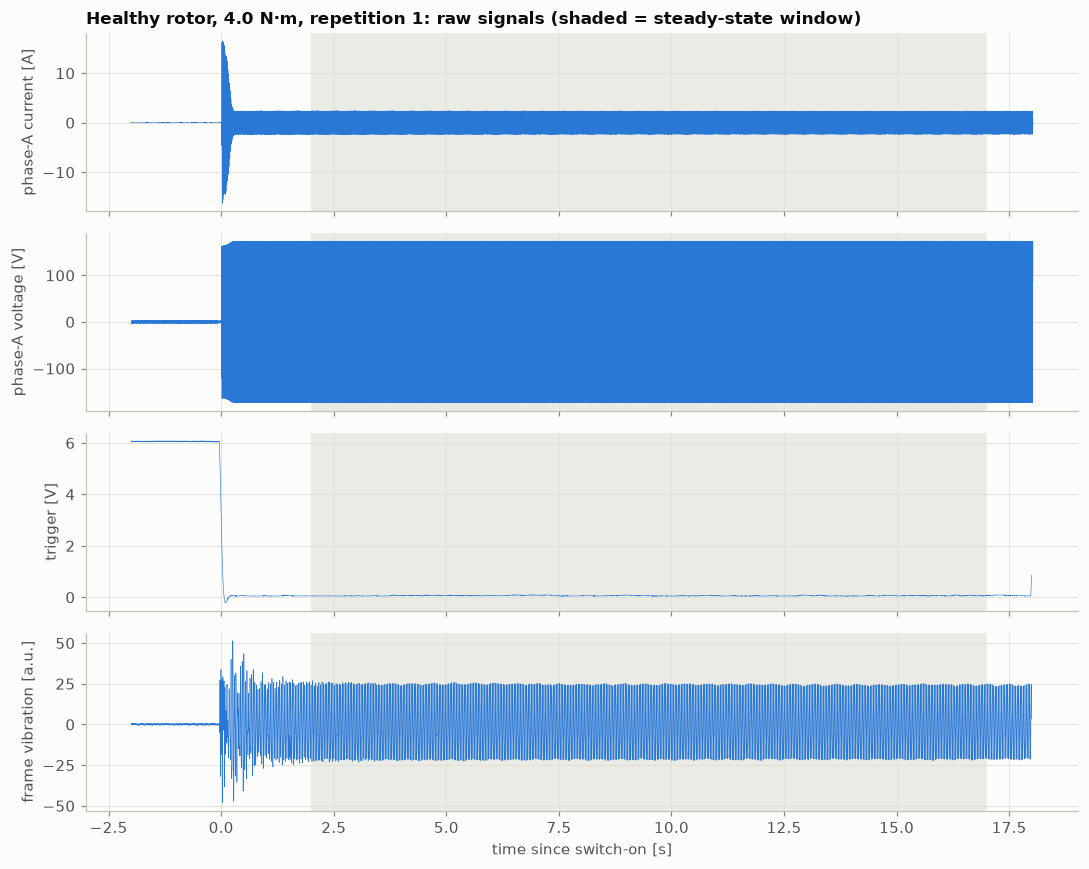

In [4]:
run = io.load_run("rs", "torque40", 0, ["Ia", "Va", "Trigger", "Vib_carc"])
on_e = dsp.current_onset(run["Ia"])
on_v = dsp.trigger_onset(run["Trigger"])
t_e = (np.arange(len(run["Ia"])) - on_e) / config.FS_ELEC
t_v = (np.arange(len(run["Trigger"])) - on_v) / config.FS_VIB

panels = [("Ia", t_e, "phase-A current [A]"), ("Va", t_e, "phase-A voltage [V]"),
          ("Trigger", t_v, "trigger [V]"), ("Vib_carc", t_v, "frame vibration [a.u.]")]
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax, (ch, t, label) in zip(axes, panels):
    ax.plot(t, run[ch], lw=0.4, color=plotting.BARS_COLORS[2])
    ax.axvspan(config.SKIP_AFTER_ONSET_S, config.SKIP_AFTER_ONSET_S + config.SEGMENT_S,
               color=plotting.GRID, alpha=0.6, lw=0)
    ax.set_ylabel(label)
axes[0].set_title("Healthy rotor, 4.0 N·m, repetition 1: raw signals (shaded = steady-state window)")
axes[-1].set_xlabel("time since switch-on [s]")
fig.tight_layout()

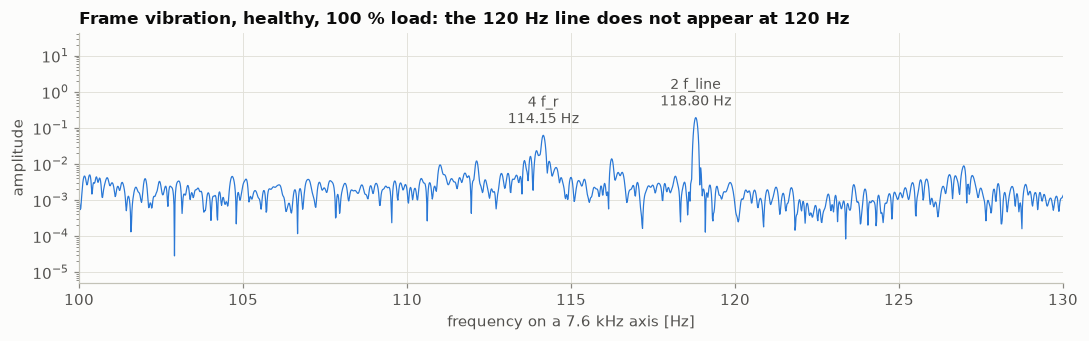

In [5]:
r = io.load_run("rs", "torque40", 0, ["Trigger", "Vib_carc"])
v = dsp.steady_segment(r["Vib_carc"], config.FS_VIB_REPORTED, dsp.trigger_onset(r["Trigger"]),
                       duration_s=None)
fr, amp = dsp.amplitude_spectrum(v, config.FS_VIB_REPORTED, fmax=200)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.semilogy(fr, amp, lw=0.8, color=plotting.BARS_COLORS[2])
for fx, label in [(dsp.peak_in_band(fr, amp, 105, 117)[0], "4 f_r"),
                  (dsp.peak_in_band(fr, amp, 117, 122)[0], "2 f_line")]:
    ax.annotate(f"{label}\n{fx:.2f} Hz", (fx, np.interp(fx, fr, amp)), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9, color=plotting.INK_2)
ax.set(xlim=(100, 130), xlabel="frequency on a 7.6 kHz axis [Hz]", ylabel="amplitude",
       title="Frame vibration, healthy, 100 % load: the 120 Hz line does not appear at 120 Hz")
fig.tight_layout()

In [6]:
seg = dsp.steady_segment(run["Va"], config.FS_ELEC, on_e)
fr, amp = dsp.amplitude_spectrum(seg, config.FS_ELEC, fmax=200)
print(f"voltage peak with fs = 50 kHz : {dsp.peak_in_band(fr, amp, 50, 70)[0]:.4f} Hz")
print(f"electrical record length      : {len(run['Va']) / config.FS_ELEC:.2f} s "
      "(documented: 18 s)")

# the 120 Hz magnetic line is exact, so where it lands on a 7.6 kHz axis gives the true rate
rows = []
for rotor in config.ROTORS:
    for torque in config.TORQUES[5:]:
        for rep in range(5):
            r = io.load_run(rotor, torque, rep, ["Trigger", "Vib_carc"])
            v = dsp.steady_segment(r["Vib_carc"], config.FS_VIB_REPORTED,
                                   dsp.trigger_onset(r["Trigger"]), duration_s=None)
            fr, amp = dsp.amplitude_spectrum(v, config.FS_VIB_REPORTED, fmax=200)
            f120, _ = dsp.peak_in_band(fr, amp, 117, 122)
            rows.append({"rotor": rotor, "torque": torque, "rep": rep,
                         "line_at_7600": f120,
                         "implied_fs": config.FS_VIB_REPORTED * 120 / f120,
                         "n_samples": len(r["Trigger"])})
fs_check = pd.DataFrame(rows)
fs_check[["line_at_7600", "implied_fs"]].describe().loc[["count", "mean", "std", "min", "max"]]

voltage peak with fs = 50 kHz : 60.0000 Hz
electrical record length      : 20.02 s (documented: 18 s)


,line_at_7600,implied_fs
count,75.000,75.000
mean,118.783,7677.858
std,0.033,2.137
min,118.719,7670.694
max,118.894,7682.015


In [7]:
fs_vib = fs_check.implied_fs.median()
print(f"estimated vibration sampling rate : {fs_vib:.0f} Hz   (config.FS_VIB = {config.FS_VIB})")
print(f"longest vibration record at {fs_vib:.0f} Hz: "
      f"{fs_check.n_samples.max() / fs_vib:.2f} s   vs electrical {1_001_000 / config.FS_ELEC:.2f} s")

estimated vibration sampling rate : 7678 Hz   (config.FS_VIB = 7677)
longest vibration record at 7678 Hz: 20.02 s   vs electrical 20.02 s


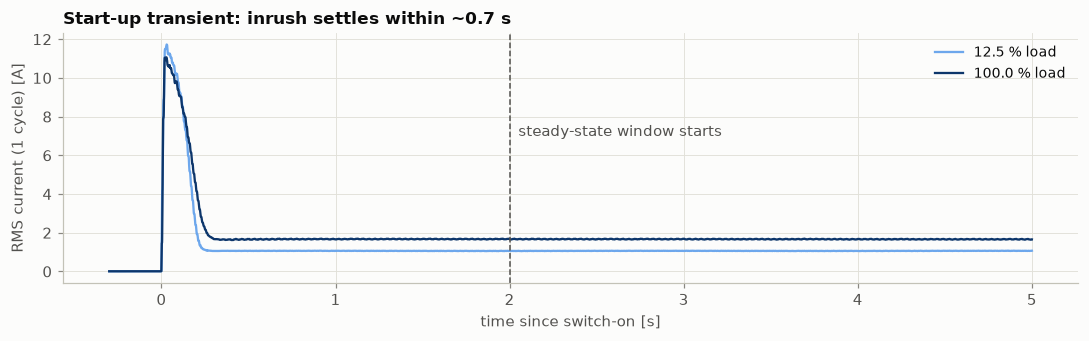

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for torque, color in [("torque05", plotting.BARS_COLORS[1]), ("torque40", plotting.BARS_COLORS[4])]:
    x = io.load_signal("rs", torque, "Ia", 0)
    on = dsp.current_onset(x)
    # RMS over one mains cycle
    w = int(config.FS_ELEC / config.LINE_FREQ)
    env = np.sqrt(np.convolve(x ** 2, np.ones(w) / w, mode="same"))
    t = (np.arange(len(x)) - on) / config.FS_ELEC
    keep = (t > -0.3) & (t < 5)
    ax.plot(t[keep], env[keep], color=color, lw=1.5,
            label=f"{config.load_pct(torque):.1f} % load")
ax.axvline(config.SKIP_AFTER_ONSET_S, color=plotting.INK_2, ls="--", lw=1)
ax.text(config.SKIP_AFTER_ONSET_S + 0.05, 7, "steady-state window starts", color=plotting.INK_2)
ax.set(xlabel="time since switch-on [s]", ylabel="RMS current (1 cycle) [A]",
       title="Start-up transient: inrush settles within ~0.7 s")
ax.legend()
fig.tight_layout()

In [9]:
import hashlib


def qc_run(rotor, torque, rep):
    r = io.load_run(rotor, torque, rep, ["Va", "Vb", "Ia", "Ib", "Ic", "Trigger"])
    fs, n = config.FS_ELEC, 5 * config.FS_ELEC
    tail = {ch: r[ch][-n:] for ch in ["Va", "Vb", "Ia", "Ib", "Ic"]}
    # phase of each channel at the supply frequency (single-bin DFT)
    kernel = np.exp(-2j * np.pi * config.LINE_FREQ * np.arange(n) / fs)
    phasor = {ch: np.sum(x * kernel) for ch, x in tail.items()}
    onset = dsp.current_onset(r["Ia"])
    return {
        "rotor": rotor, "torque": torque, "rep": rep,
        "n_elec": len(r["Ia"]), "n_vib": len(r["Trigger"]),
        "onset_s": np.nan if onset is None else onset / fs,
        "trigger_onset_s": dsp.trigger_onset(r["Trigger"]) / config.FS_VIB,
        **{f"rms_{ch}": x.std() for ch, x in tail.items()},
        "vb_angle": np.angle(phasor["Vb"] / phasor["Va"], deg=True) % 360,
        "ia_angle": np.angle(phasor["Ia"] / phasor["Va"], deg=True) % 360,
        # identical hashes mean a duplicated recording
        "ia_md5": hashlib.md5(r["Ia"].tobytes()).hexdigest(),
    }

qc = pd.DataFrame([qc_run(*key) for key in io.iter_run_keys(skip_bad=False)])
qc.to_csv(config.RESULTS_DIR / "qc_runs.csv", index=False)
print(qc.shape)

(400, 15)


In [10]:
# a dead channel carries almost no current
dead = qc[(qc[["rms_Ia", "rms_Ib", "rms_Ic"]] < 0.05).any(axis=1)]
dead[["rotor", "torque", "rep", "rms_Va", "rms_Ia", "rms_Ib", "rms_Ic", "onset_s"]]

,rotor,torque,rep,rms_Va,rms_Ia,rms_Ib,rms_Ic,onset_s
8,rs,torque05,8,2.16,0.007,0.006,0.006,NaN


In [11]:
dupes = qc[qc.duplicated("ia_md5", keep=False) & (qc.rms_Ia > 0.05)]
dupes[["rotor", "torque", "rep", "rms_Ia", "onset_s", "ia_md5"]]

,rotor,torque,rep,rms_Ia,onset_s,ia_md5
320,r4b,torque05,0,1.121,1.993,38a5a32b9bcedfacff256c8f2f5153d8
399,r4b,torque40,9,1.121,1.993,38a5a32b9bcedfacff256c8f2f5153d8


In [12]:
bad = [(r.rotor, r.torque, r.rep) in config.BAD_RUNS for r in qc.itertuples()]
good = qc[~np.array(bad)]
print(f"{len(good)} good runs")
print("electrical samples :", good.n_elec.unique(), "->", good.n_elec.unique() / config.FS_ELEC, "s")
print("vibration samples  :", good.n_vib.min(), "-", good.n_vib.max())
print("switch-on (current):", f"{good.onset_s.min():.3f} - {good.onset_s.max():.3f} s")
print("switch-on (trigger):", f"{good.trigger_onset_s.min():.3f} - {good.trigger_onset_s.max():.3f} s")
print("runs with switch-on far from 1.99 s:")
print(good[(good.onset_s - 1.993).abs() > 0.05][["rotor", "torque", "rep", "onset_s"]].to_string(index=False))

# the steady-state window must end before the record does
window_end = good.onset_s + config.SKIP_AFTER_ONSET_S + config.SEGMENT_S
print(f"\nlatest steady-state window end: {window_end.max():.2f} s "
      f"(record length {good.n_elec.max() / config.FS_ELEC:.2f} s) -> fits: "
      f"{(window_end < good.n_elec / config.FS_ELEC).all()}")

398 good runs
electrical samples : [1001000] -> [20.02] s
vibration samples  : 142559 - 153741
switch-on (current): 1.771 - 2.796 s
switch-on (trigger): 0.530 - 2.000 s
runs with switch-on far from 1.99 s:
rotor   torque  rep  onset_s
   rs torque15    9    2.796
  r1b torque10    4    1.929
  r3b torque05    6    1.813
  r3b torque15    2    1.888
  r3b torque30    5    1.917
  r4b torque05    7    1.939
  r4b torque10    5    1.845
  r4b torque25    2    1.838
  r4b torque25    5    1.819
  r4b torque35    8    1.771
  r4b torque40    3    1.917

latest steady-state window end: 19.80 s (record length 20.02 s) -> fits: True


In [13]:
phase = pd.DataFrame({
    "Vb_vs_Va_deg": good.groupby("rotor").vb_angle.median(),
    "Vb_vs_Va_spread": good.groupby("rotor").vb_angle.agg(lambda s: s.max() - s.min()),
    "Ia_vs_Va_deg_full_load": good[good.torque == "torque40"].groupby("rotor").ia_angle.median(),
}).loc[list(config.ROTORS)]
phase.round(1)

,Vb_vs_Va_deg,Vb_vs_Va_spread,Ia_vs_Va_deg_full_load
rotor,,,
rs,239.9,0.3,231.2
r1b,120.1,0.3,349.9
r2b,120.0,0.4,351.0
r3b,120.0,0.3,350.3
r4b,120.0,0.3,348.1
